In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import Perceptron

from sklearn.metrics import accuracy_score, classification_report,confusion_matrix

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import Flatten

from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import Dropout

from tensorflow.keras.utils import to_categorical

In [2]:
df = pd.read_csv("mnist_train.csv")
df_test = pd.read_csv("mnist_test.csv")

In [3]:
df.head()

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,5,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,4,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,9,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
df.shape

(39004, 785)

In [5]:
df.columns

Index(['label', '1x1', '1x2', '1x3', '1x4', '1x5', '1x6', '1x7', '1x8', '1x9',
       ...
       '28x19', '28x20', '28x21', '28x22', '28x23', '28x24', '28x25', '28x26',
       '28x27', '28x28'],
      dtype='object', length=785)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39004 entries, 0 to 39003
Columns: 785 entries, label to 28x28
dtypes: float64(584), int64(201)
memory usage: 233.6 MB


In [7]:
df.isnull().sum()

,0
label,0
1x1,0
1x2,0
1x3,0
1x4,0
...,...
28x24,1
28x25,1
28x26,1
28x27,1


In [8]:
X_train = df.drop("label",axis=1).values
y_train = df["label"].values
X_test = df_test.drop("label",axis=1).values
y_test = df_test["label"].values

In [9]:
X_train = X_train.astype("float32")/255.0
X_test = X_test.astype("float32")/255.0

In [10]:
X_train_img = X_train.reshape(-1,28,28)
X_test_img = X_test.reshape(-1,28,28)

In [11]:
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

In [12]:
perceptron = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(10, activation="softmax")
])

In [13]:
perceptron.compile(optimizer="sgd",loss="categorical_crossentropy",metrics=["accuracy"])

In [14]:
history_percp = perceptron.fit(X_train_img,y_train_cat,epochs=5,batch_size=32,validation_data=(X_test_img,y_test_cat),verbose=1)

Epoch 1/5
1219/1219 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.1382 - loss: nan - val_accuracy: 0.1009 - val_loss: nan
Epoch 2/5
1219/1219 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.1004 - loss: nan - val_accuracy: 0.1009 - val_loss: nan
Epoch 3/5
1219/1219 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.1004 - loss: nan - val_accuracy: 0.1009 - val_loss: nan
Epoch 4/5
1219/1219 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.1004 - loss: nan - val_accuracy: 0.1009 - val_loss: nan
Epoch 5/5
1219/1219 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.1004 - loss: nan - val_accuracy: 0.1009 - val_loss: nan


In [15]:
acc_percp = perceptron.evaluate(X_test_img,y_test_cat,verbose=0)[1]

In [16]:
acc_percp

0.10090000182390213

In [17]:
ann = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

In [18]:
ann.compile(optimizer="adam",loss="categorical_crossentropy",metrics=["accuracy"])

In [19]:
history_ann = ann.fit(X_train_img,y_train_cat,epochs=5,batch_size=32,validation_data=(X_test_img,y_test_cat),verbose=1)

Epoch 1/5
1219/1219 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.1064 - loss: nan - val_accuracy: 0.1009 - val_loss: nan
Epoch 2/5
1219/1219 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.1004 - loss: nan - val_accuracy: 0.1009 - val_loss: nan
Epoch 3/5
1219/1219 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.1004 - loss: nan - val_accuracy: 0.1009 - val_loss: nan
Epoch 4/5
1219/1219 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.1004 - loss: nan - val_accuracy: 0.1009 - val_loss: nan
Epoch 5/5
1219/1219 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.1004 - loss: nan - val_accuracy: 0.1009 - val_loss: nan


In [20]:
acc_ann = ann.evaluate(X_test_img,y_test_cat,verbose=0)[1]

In [21]:
acc_ann

0.10090000182390213

In [22]:
X_train_cnn = X_train.reshape(-1,28,28,1)
X_test_cnn = X_test.reshape(-1,28,28,1)

In [23]:
cnn = Sequential([
    Conv2D(32,kernel_size=(3,3),activation="relu",input_shape=(28,28,1)),
    MaxPooling2D(pool_size=(2,2)),
    Conv2D(64,kernel_size=(3,3),activation="relu"),
    MaxPooling2D(pool_size=(2,2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(10, activation="softmax")
])

In [24]:
cnn.compile(optimizer="adam",loss="categorical_crossentropy",metrics=["accuracy"])

In [25]:
history_cnn = cnn.fit(X_train_cnn,y_train_cat,epochs=5,batch_size=32,validation_data=(X_test_cnn,y_test_cat),verbose=1)

Epoch 1/5
1219/1219 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.2731 - loss: nan - val_accuracy: 0.1009 - val_loss: nan
Epoch 2/5
1219/1219 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.1004 - loss: nan - val_accuracy: 0.1009 - val_loss: nan
Epoch 3/5
1219/1219 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.1004 - loss: nan - val_accuracy: 0.1009 - val_loss: nan
Epoch 4/5
1219/1219 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.1004 - loss: nan - val_accuracy: 0.1009 - val_loss: nan
Epoch 5/5
1219/1219 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.1004 - loss: nan - val_accuracy: 0.1009 - val_loss: nan


In [26]:
ann_cnn = cnn.evaluate(X_test_cnn,y_test_cat,verbose=0)[1]

In [27]:
ann_cnn

0.10090000182390213

In [28]:
def plot_training(history, title):
  plt.figure(figsize=(12,4))
  plt.subplot(1,2,1)
  plt.plot(history.history['accuracy'], label='Train')
  plt.plot(history.history['val_accuracy'], label='Val')
  plt.title(f'{title} Accuracy')
  plt.legend()

  plt.subplot(1,2,2)
  plt.plot(history.history['loss'], label='Train')
  plt.plot(history.history['val_loss'], label='Val')
  plt.title(f'{title} Loss')
  plt.legend()
  plt.show()

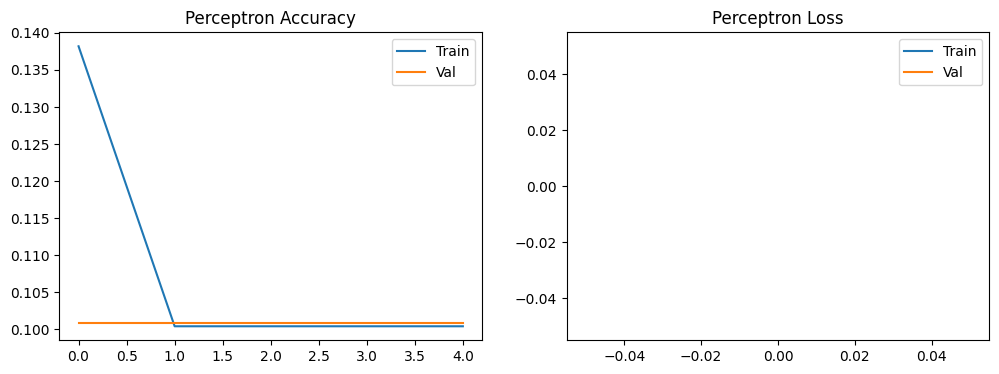

In [29]:
plot_training(history_percp,"Perceptron")

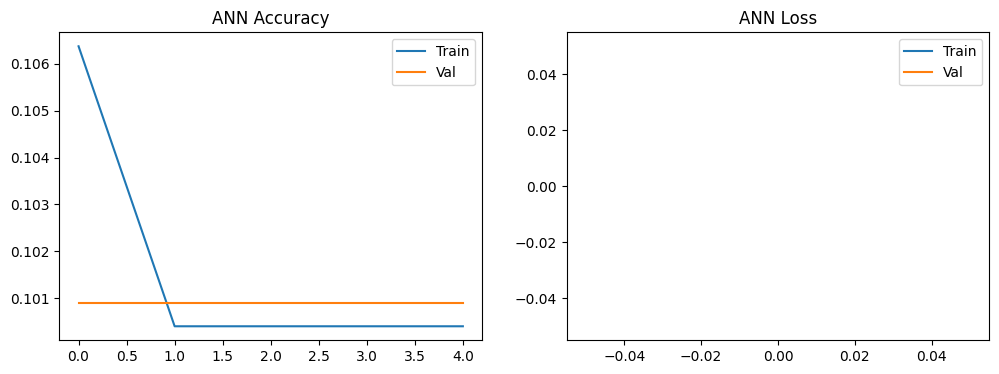

In [30]:
plot_training(history_ann,"ANN")

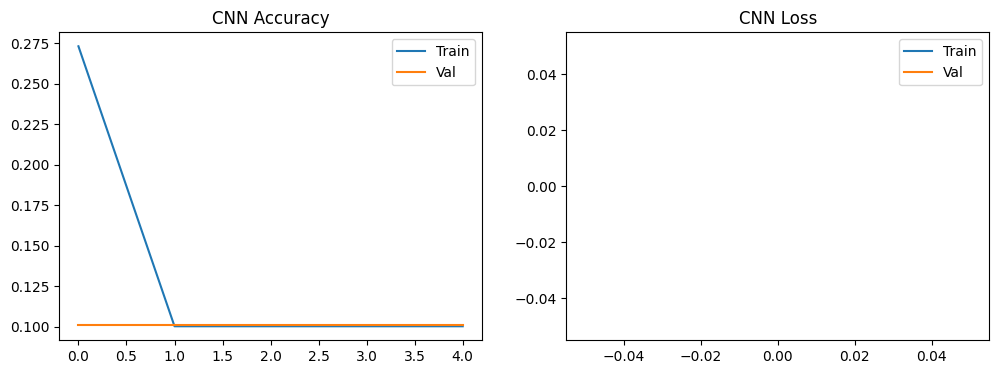

In [31]:
plot_training(history_cnn,"CNN")

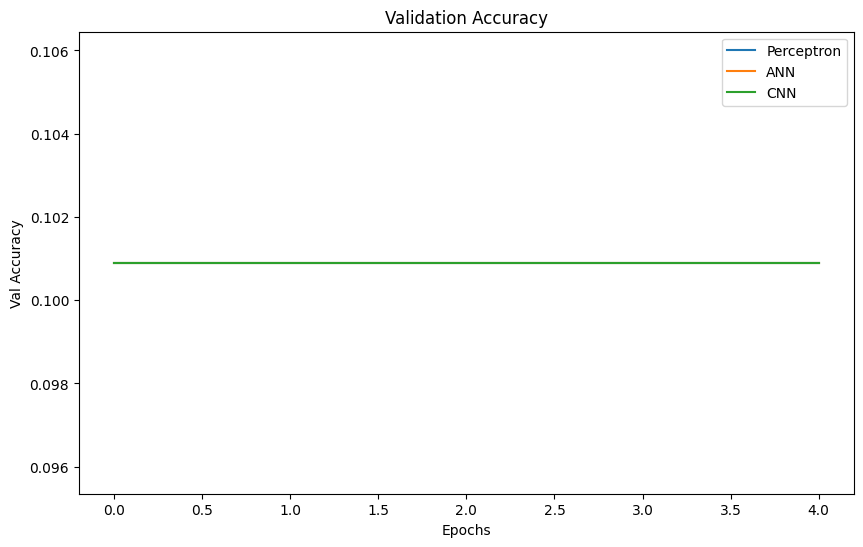

In [32]:
plt.figure(figsize=(10,6))
plt.plot(history_percp.history["val_accuracy"], label="Perceptron")
plt.plot(history_ann.history["val_accuracy"], label="ANN")
plt.plot(history_cnn.history["val_accuracy"], label="CNN")
plt.title("Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Val Accuracy")
plt.legend()
plt.show()

In [35]:
def show_side_by_side(models,model_names,X,X_cnn,y_true,n=5):
  idxs = np.random.choice(len(X),n,replace=False)
  plt.figure(figsize=(15,6))
  for i,idx in enumerate(idxs):
    plt.subplot(2,n,i+1)
    plt.imshow(X[idx].reshape(28,28),cmap="gray")
    plt.axis("off")
    plt.title(f"True: {y_true[idx]}")
    preds = [np.argmax(model.predict(X_cnn[idx].reshape(1,28,28,1) if name == "CNN" else X[idx].reshape(1,28,28)))
    for model,name in zip(models,model_names)]
    plt.subplot(2,n,n+i+1)
    plt.axis("off")
    plt.title("\n".join(f"{n}: {p}" for n,p in zip(model_names,preds)))
  plt.tight_layout()
  plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


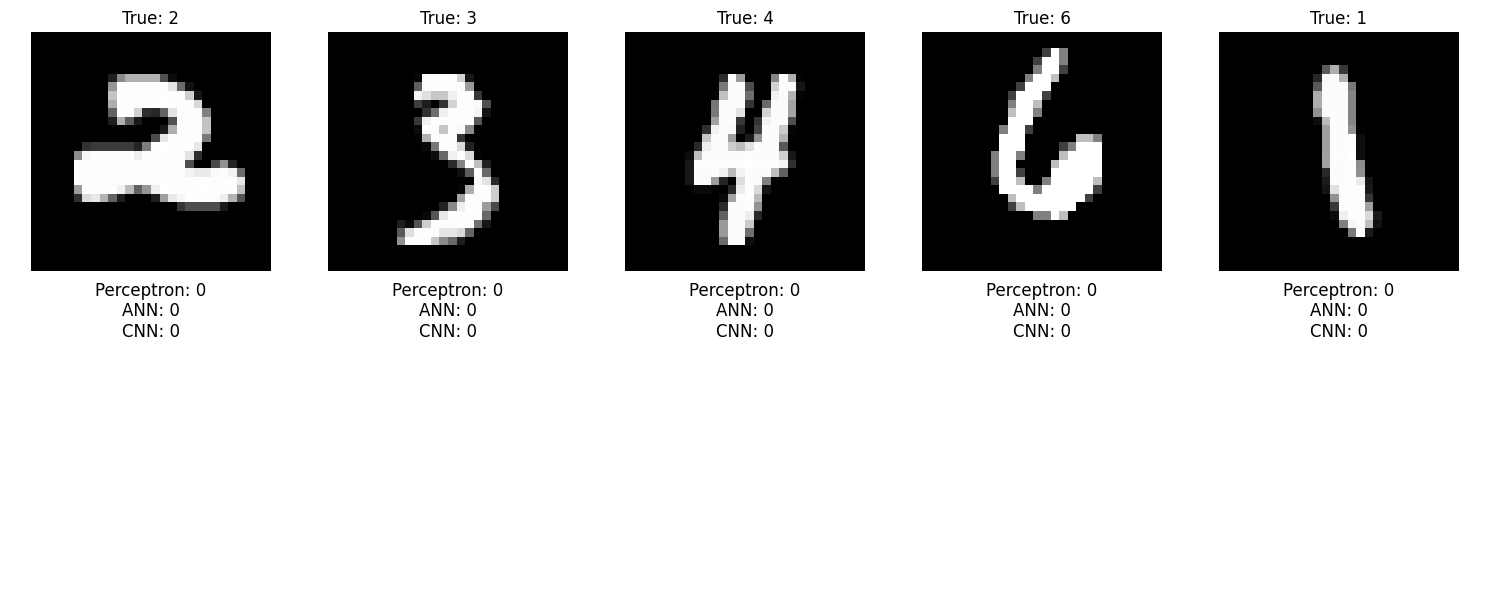

In [36]:
show_side_by_side([perceptron,ann,cnn],["Perceptron","ANN","CNN"],X_test,X_test_cnn,y_test,5)